In [1]:
%pip install pubchempy

In [3]:
%pip install rdkit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 64.7 MB/s  0:00:00


In [4]:
import pubchempy as pcp
import pandas as pd
from rdkit import Chem
from rdkit.Chem import AllChem, Descriptors

In [5]:
drug_names = ["Aspirin", "Ibuprofen", "Naproxen", "Diclofenac", "Paracetamol"]

In [7]:
compound_data = []

for name in drug_names:
    # Get compounds matching the name (taking the first/best match)
    results = pcp.get_compounds(name, 'name')
    if results:
        comp = results[0]
        compound_data.append({
            "Name": name,
            "CID": comp.cid,
            "SMILES": comp.canonical_smiles,
            "PubChem_MW": comp.molecular_weight
        })

/tmp/ipykernel_361/1107595508.py:11: PubChemPyDeprecationWarning: canonical_smiles is deprecated: Use connectivity_smiles instead
  "SMILES": comp.canonical_smiles,


In [8]:
df = pd.DataFrame(compound_data)
print(df[['Name', 'CID', 'PubChem_MW', 'SMILES']])

          Name     CID  PubChem_MW                                    SMILES
0      Aspirin    2244      180.16                  CC(=O)OC1=CC=CC=C1C(=O)O
1    Ibuprofen    3672      206.28             CC(C)CC1=CC=C(C=C1)C(C)C(=O)O
2     Naproxen  156391      230.26       CC(C1=CC2=C(C=C1)C=C(C=C2)OC)C(=O)O
3   Diclofenac    3033      296.10  C1=CC=C(C(=C1)CC(=O)O)NC2=C(C=CC=C2Cl)Cl
4  Paracetamol    1983      151.16                     CC(=O)NC1=CC=C(C=C1)O


In [9]:
# 4. Convert PubChem SMILES into RDKit Mol objects
df['Mol'] = df['SMILES'].apply(Chem.MolFromSmiles)

# 5. Generate Morgan Fingerprints (Radius 2, 2048 bits)
df['Fingerprint'] = df['Mol'].apply(lambda m: AllChem.GetMorganFingerprintAsBitVect(m, radius=2, nBits=2048))

print("\nSuccessfully fetched structures from PubChem and generated RDKit fingerprints!")


Successfully fetched structures from PubChem and generated RDKit fingerprints!


[11:22:03] DEPRECATION WARNING: please use MorganGenerator
[11:22:03] DEPRECATION WARNING: please use MorganGenerator
[11:22:03] DEPRECATION WARNING: please use MorganGenerator
[11:22:03] DEPRECATION WARNING: please use MorganGenerator
[11:22:03] DEPRECATION WARNING: please use MorganGenerator


In [10]:
from rdkit.Chem import Draw

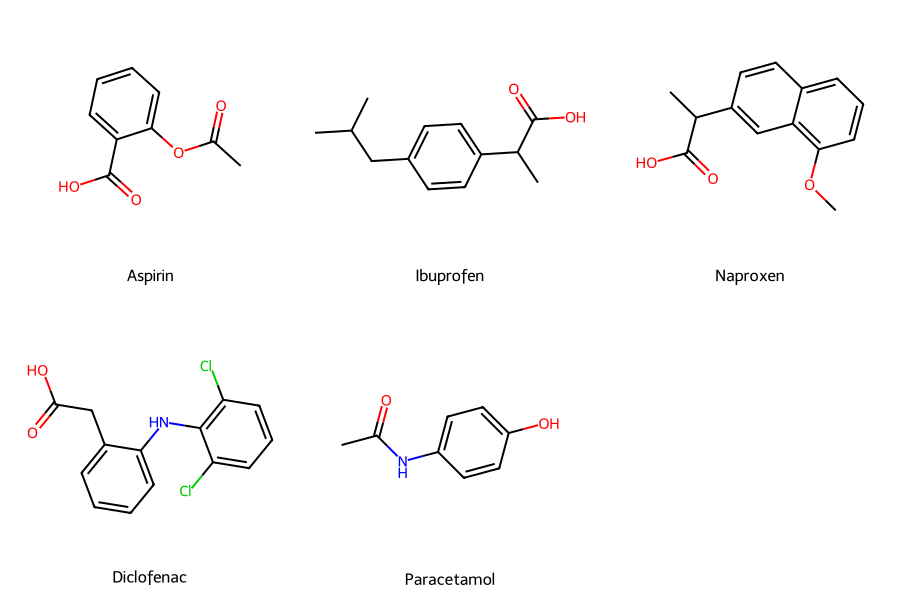

In [14]:
# List of our 5 drug SMILES strings
smiles_list = [
    "CC(=O)Oc1ccccc1C(=O)O",          # Aspirin
    "CC(C)Cc1ccc(cc1)C(C)C(=O)O",      # Ibuprofen
    "CC(C1=CC2=C(C=C1)C=CC=C2OC)C(=O)O", # Naproxen
    "OC(=O)Cc1ccccc1Nc2c(Cl)cccc2Cl",  # Diclofenac
    "CC(=O)Nc1ccc(O)cc1"               # Paracetamol
]

names = ["Aspirin", "Ibuprofen", "Naproxen", "Diclofenac", "Paracetamol"]

# Convert SMILES to RDKit Mol objects
mols = [Chem.MolFromSmiles(s) for s in smiles_list]

# Draw a grid of molecules with their names as legends
img = Draw.MolsToGridImage(mols, molsPerRow=3, subImgSize=(300, 300), legends=names)

display(img)

In [15]:
data = []
for name in drug_names:
    results = pcp.get_compounds(name, 'name')
    if results:
        comp = results[0]
        smiles = comp.canonical_smiles
        mol = Chem.MolFromSmiles(smiles)
        if mol:
            data.append({
                "Name": name,
                "SMILES": smiles,
                "MW": round(Descriptors.MolWt(mol), 2),
                "LogP": round(Descriptors.MolLogP(mol), 2),
                "H_Donors": Descriptors.NumHDonors(mol),
                "H_Acceptors": Descriptors.NumHAcceptors(mol)
            })

df = pd.DataFrame(data)

/tmp/ipykernel_361/727560611.py:6: PubChemPyDeprecationWarning: canonical_smiles is deprecated: Use connectivity_smiles instead
  smiles = comp.canonical_smiles


In [17]:
#Check Lipinski's Rule of Five
df['Lipinski_Pass'] = (
    (df['MW'] <= 500) &
    (df['LogP'] <= 5) &
    (df['H_Donors'] <= 5) &
    (df['H_Acceptors'] <= 10)
)

print(df[['Name', 'MW', 'LogP', 'H_Donors', 'H_Acceptors', 'Lipinski_Pass']])

          Name      MW  LogP  H_Donors  H_Acceptors  Lipinski_Pass
0      Aspirin  180.16  1.31         1            3           True
1    Ibuprofen  206.28  3.07         1            1           True
2     Naproxen  230.26  3.04         1            2           True
3   Diclofenac  296.15  4.36         2            2           True
4  Paracetamol  151.16  1.35         2            2           True


In [21]:
from rdkit import DataStructs

In [22]:
# 1. Ensure we have our Mol objects and generate Morgan Fingerprints (radius=2, 2048 bits)
df['Fingerprint'] = df['SMILES'].apply(lambda s: AllChem.GetMorganFingerprintAsBitVect(Chem.MolFromSmiles(s), radius=2, nBits=2048))

names = df['Name'].tolist()
fps = df['Fingerprint'].tolist()

[11:38:49] DEPRECATION WARNING: please use MorganGenerator
[11:38:49] DEPRECATION WARNING: please use MorganGenerator
[11:38:49] DEPRECATION WARNING: please use MorganGenerator
[11:38:49] DEPRECATION WARNING: please use MorganGenerator
[11:38:49] DEPRECATION WARNING: please use MorganGenerator


In [23]:
# 2. Compute the pairwise Tanimoto similarity matrix
similarity_matrix = []
for i, fp1 in enumerate(fps):
    row = []
    for j, fp2 in enumerate(fps):
        sim = DataStructs.TanimotoSimilarity(fp1, fp2)
        row.append(round(sim, 2)) # Rounded to 2 decimal places
    similarity_matrix.append(row)

In [24]:
sim_df = pd.DataFrame(similarity_matrix, index=names, columns=names)

print("Pairwise Tanimoto Similarity Matrix:")
print(sim_df)

Pairwise Tanimoto Similarity Matrix:
             Aspirin  Ibuprofen  Naproxen  Diclofenac  Paracetamol
Aspirin         1.00       0.20      0.20        0.20         0.22
Ibuprofen       0.20       1.00      0.42        0.17         0.18
Naproxen        0.20       0.42      1.00        0.13         0.17
Diclofenac      0.20       0.17      0.13        1.00         0.16
Paracetamol     0.22       0.18      0.17        0.16         1.00


In [26]:
similarity_matrix = []
for fp1 in fps:
    row = [round(DataStructs.TanimotoSimilarity(fp1, fp2), 2) for fp2 in fps]
    similarity_matrix.append(row)

sim_df = pd.DataFrame(similarity_matrix, index=names, columns=names)

In [28]:
import seaborn as sns
import matplotlib.pyplot as plt

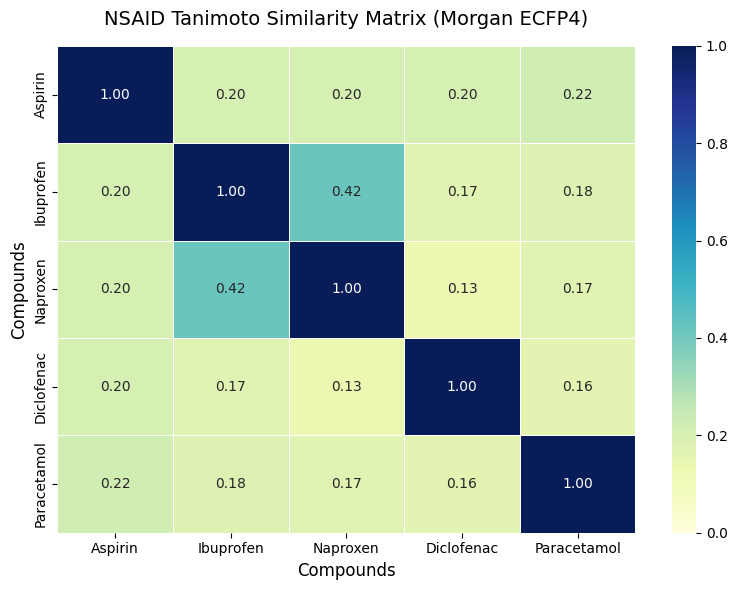

In [29]:
# 3. Plot the Heatmap using Seaborn
plt.figure(figsize=(8, 6))
sns.heatmap(
    sim_df,
    annot=True,         # Display the numeric score in each cell
    cmap="YlGnBu",      # Yellow-Green-Blue color palette (darker = higher similarity)
    vmin=0.0, vmax=1.0, # Scale from 0 to 1
    linewidths=0.5,     # Grid lines between cells
    fmt=".2f"           # Two decimal places
)

plt.title("NSAID Tanimoto Similarity Matrix (Morgan ECFP4)", fontsize=14, pad=15)
plt.xlabel("Compounds", fontsize=12)
plt.ylabel("Compounds", fontsize=12)
plt.tight_layout()
plt.show()